In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# this code is an example for performing 2d convolution from scratch

In [3]:
# kernel = np.ones((3, 3)) / 9
# kernel = np.array(
#     [[1, 2, 1],[2, 4, 2], [1,2 ,1]]
# ) / 16


kernel = np.array([
    [1, 4, 6, 4, 1],
    [4,16,24,16,4],
    [6,24,36,24,6],
    [4,16,24,16,4],
    [1, 4, 6, 4, 1]
], dtype=np.float32) / 256


In [4]:
import numpy as np

# Create a 21x21 Gaussian-like kernel
size = 21
# Create 1D Gaussian weights
x = np.linspace(-10, 10, size)
gauss_1d = np.exp(-0.5 * (x/3)**2)  # sigma ~ 3
gauss_1d /= gauss_1d.sum()           # normalize 1D

# Create 2D Gaussian by outer product
kernel = np.outer(gauss_1d, gauss_1d)
kernel /= kernel.sum()          # normalize 2D

print(kernel.shape)
print(kernel)


(21, 21)
[[2.64523184e-07 7.60126187e-07 1.95457665e-06 4.49743374e-06
  9.26023269e-06 1.70617700e-05 2.81301031e-05 4.15014836e-05
  5.47899594e-05 6.47266890e-05 6.84243788e-05 6.47266890e-05
  5.47899594e-05 4.15014836e-05 2.81301031e-05 1.70617700e-05
  9.26023269e-06 4.49743374e-06 1.95457665e-06 7.60126187e-07
  2.64523184e-07]
 [7.60126187e-07 2.18427667e-06 5.61661504e-06 1.29236958e-05
  2.66099374e-05 4.90282098e-05 8.08338524e-05 1.19257466e-04
  1.57442846e-04 1.85996746e-04 1.96622320e-04 1.85996746e-04
  1.57442846e-04 1.19257466e-04 8.08338524e-05 4.90282098e-05
  2.66099374e-05 1.29236958e-05 5.61661504e-06 2.18427667e-06
  7.60126187e-07]
 [1.95457665e-06 5.61661504e-06 1.44424765e-05 3.32317902e-05
  6.84243788e-05 1.26070376e-04 2.07854910e-04 3.06656791e-04
  4.04846084e-04 4.78269136e-04 5.05591574e-04 4.78269136e-04
  4.04846084e-04 3.06656791e-04 2.07854910e-04 1.26070376e-04
  6.84243788e-05 3.32317902e-05 1.44424765e-05 5.61661504e-06
  1.95457665e-06]
 [4.497

In [5]:
kernel

array([[2.64523184e-07, 7.60126187e-07, 1.95457665e-06, 4.49743374e-06,
        9.26023269e-06, 1.70617700e-05, 2.81301031e-05, 4.15014836e-05,
        5.47899594e-05, 6.47266890e-05, 6.84243788e-05, 6.47266890e-05,
        5.47899594e-05, 4.15014836e-05, 2.81301031e-05, 1.70617700e-05,
        9.26023269e-06, 4.49743374e-06, 1.95457665e-06, 7.60126187e-07,
        2.64523184e-07],
       [7.60126187e-07, 2.18427667e-06, 5.61661504e-06, 1.29236958e-05,
        2.66099374e-05, 4.90282098e-05, 8.08338524e-05, 1.19257466e-04,
        1.57442846e-04, 1.85996746e-04, 1.96622320e-04, 1.85996746e-04,
        1.57442846e-04, 1.19257466e-04, 8.08338524e-05, 4.90282098e-05,
        2.66099374e-05, 1.29236958e-05, 5.61661504e-06, 2.18427667e-06,
        7.60126187e-07],
       [1.95457665e-06, 5.61661504e-06, 1.44424765e-05, 3.32317902e-05,
        6.84243788e-05, 1.26070376e-04, 2.07854910e-04, 3.06656791e-04,
        4.04846084e-04, 4.78269136e-04, 5.05591574e-04, 4.78269136e-04,
        4.0484

In [6]:
import cv2

In [7]:
img = cv2.imread("bird.png")
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
img = img.astype(np.float32)

In [8]:
# img

In [9]:
img_channel1 = img[:, :, 0]
img_channel2 = img[:, :, 1]
img_channel3 = img[:, :, 2]

In [10]:
img_channel1.shape

(2000, 1333)

In [11]:
og_img_channel1 = img_channel1

In [12]:
img_channel1.shape

(2000, 1333)

In [23]:
def blur(img, kernel):
    kernel_dim = kernel.shape[0]
    res = np.zeros(img.shape)
    for i in range(img.shape[0]):
        for j in range(img.shape[1]):
            # print(f"[{i}: {i+kernel_dim}, {j}: {j + kernel_dim}]")
            if i + kernel_dim < img.shape[0] and j + kernel_dim < img.shape[1]:
                sub = np.sum(kernel  * img[i:i+kernel_dim, j:j+kernel_dim])
                res[i+kernel_dim//2, j+kernel_dim//2] = sub
    return res

In [14]:
blurring_intensity = 10
for i in range(blurring_intensity):
    print(f"{i} blurring iterations done")
    
    img_channel1 = blur(img_channel1)


0 blurring iterations done
1 blurring iterations done
2 blurring iterations done
3 blurring iterations done
4 blurring iterations done
5 blurring iterations done
6 blurring iterations done
7 blurring iterations done
8 blurring iterations done
9 blurring iterations done


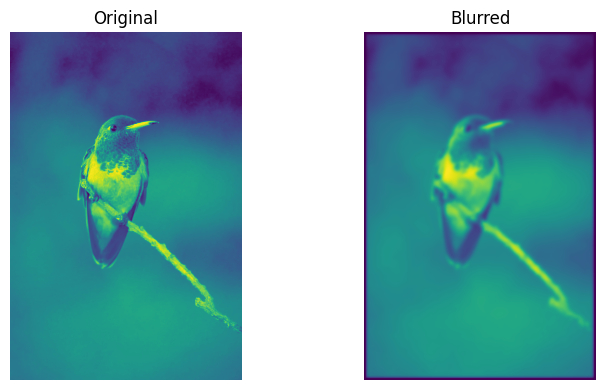

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(8, 4))

axs[0].imshow(og_img_channel1)
axs[0].set_title("Original")
axs[0].axis("off")

axs[1].imshow(img_channel1)
axs[1].set_title("Blurred")
axs[1].axis("off")

plt.tight_layout()
plt.show()

# plt.imshow(np.concat((img_channel1.reshape(2000, 1333, 1), img_channel2.reshape(2000, 1333, 1), img_channel3.reshape(2000, 1333, 1)), axis=2))